# 현재 구간만 사용하는 장기 이상 탐지 개선

1시간 모드의 정상 분포 학습을 개선한 결과다. 4·8·12·24시간 모델은 그대로 보존했다. **이전·다음 감시 배치나 누적 경보 상태를 사용하지 않는다.**

정상 참고 자료는 과거 28일이다. 현재 1시간 입력은 여전히 한 점이며, 이 점을 정상 분포와 비교한다. 현재 한 시간만으로 장기 추세를 직접 관측한다는 뜻은 아니다.

## 1. 평가 범위와 목표

- 지속 지연, 점진적 악화, 지속 폭주, 지속 입력 감소, 일일 패턴 변화, 변동성 증가의 여섯 시나리오를 모두 평가했다.
- 목표는 각 입력 길이에서 시나리오별 Accuracy·Precision·Recall·F1의 중앙값 각각 65% 이상이다. 오탐률은 전체·각 시나리오에서 6% 이하를 별도로 확인한다.
- 평가 단위는 원래 관측된 한 시간이다. 정답 확장·point adjustment·어려운 시나리오 제외는 없다.
- 기존 반합성 평가셋을 재사용했다. 새로운 독립 블라인드 평가가 아니며 실제 운영 장애 성능으로 주장하지 않는다. 평가셋과 주입 강도를 수정하지 않았다.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
cwd = Path.cwd()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / 'data/evaluation_long_term/manifest.json').exists())
if str(ROOT / 'code') not in sys.path:
    sys.path.insert(0, str(ROOT / 'code'))
from long_term_anomaly.common import read_json
from long_term_anomaly.strict_refinement.report import table, scenario_table
OUT = ROOT / 'reports/long_term_anomaly/strict_refinement'
results = read_json(OUT / 'results.json')
pd.options.display.float_format = '{:.2f}'.format
display(Markdown(f"각 길이에서 동일한 **{results['results']['1']['pooled']['assessed_hours']:,}개 관측 시간**을 평가했다. 전체 목표 달성 여부: **{results['goal_met_all_lengths']}**."))

각 길이에서 동일한 **192,178개 관측 시간**을 평가했다. 전체 목표 달성 여부: **False**.

## 2. 최신 전체 성능

아래 Accuracy·Precision·Recall·F1은 **여섯 시나리오 지표의 중앙값**이다. 모든 시나리오 각각 65%라는 뜻이 아니며 모든 시간을 합친 통합 지표와도 다르다. 각 지표를 시나리오별로 계산한 뒤 각각 중앙값을 구하므로, 중앙값 Precision·Recall로 F1을 재계산한 값과도 다를 수 있다.

Recall은 실제 이상 중 탐지한 비율이므로 높을수록 덜 놓친다. Precision은 경보 중 실제 이상 비율이다. F1은 두 값을 함께 보며, Accuracy는 정상 비중이 크면 이상을 놓쳐도 높을 수 있다.

목표 통과 여부는 숫자로 따로 검증한다. 그림에는 최소 목표선이나 목표 수치를 넣지 않고 실제 측정값만 표시했다.

,분석 구간,Accuracy,Precision,Recall,F1,전체 오탐률,시나리오 최대 오탐률
0,1시간,88.69,70.27,59.72,64.56,5.30,5.89
1,4시간,90.94,75.93,69.67,72.74,3.72,4.69
2,8시간,92.29,80.88,75.95,75.87,3.71,5.37
3,12시간,92.81,78.38,76.53,77.39,4.14,5.17
4,24시간,93.44,78.23,80.90,79.86,3.89,5.64


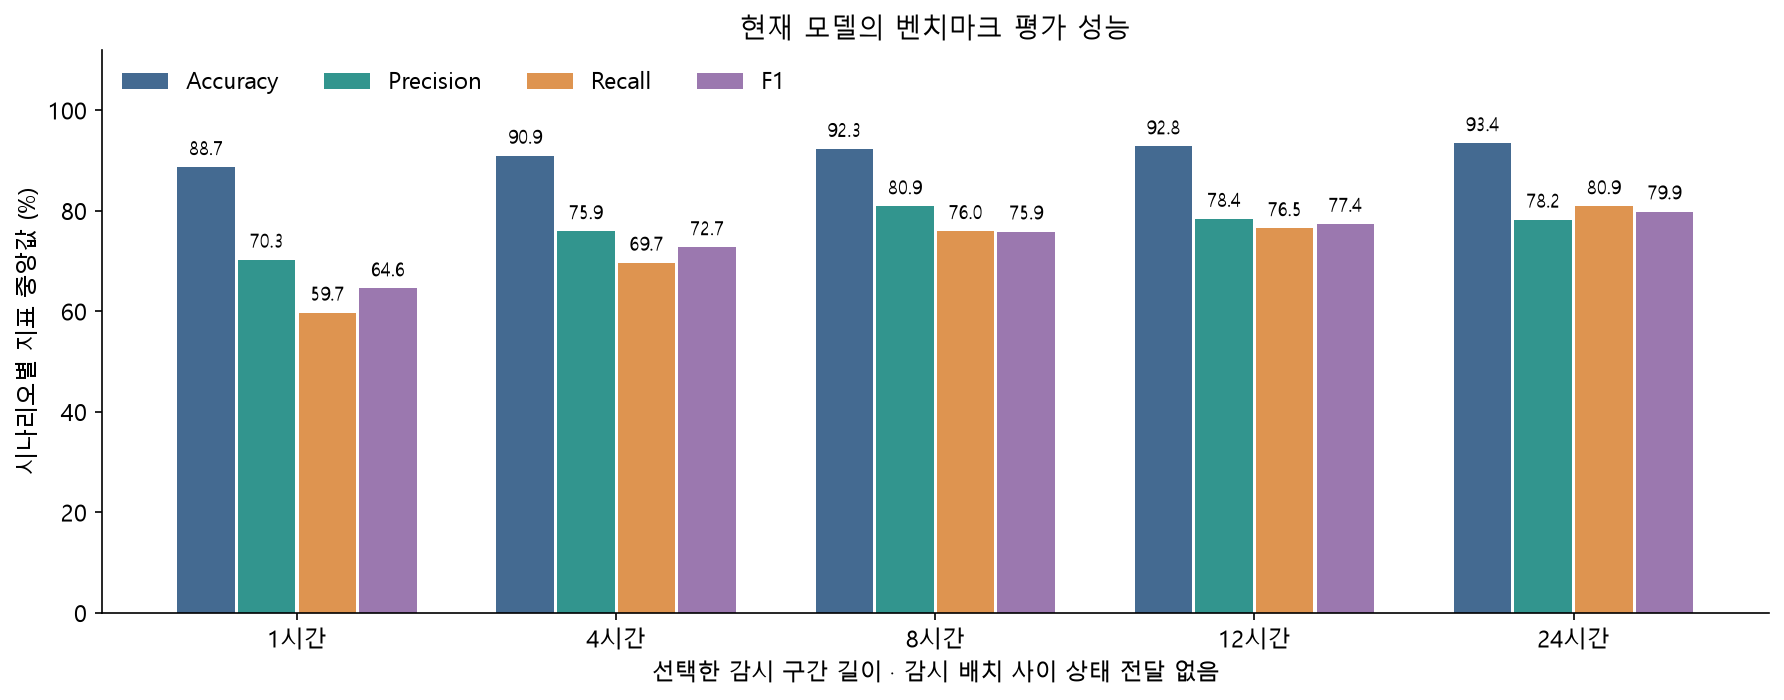

,분석 구간,중앙값 및 오탐률 목표 충족
0,1시간,False
1,4시간,True
2,8시간,True
3,12시간,True
4,24시간,True


In [2]:
display(table())
display(Image(filename=str(OUT / 'figures/metrics_median.png')))
display(pd.DataFrame([{'분석 구간': f'{h}시간', '중앙값 및 오탐률 목표 충족': r['target_met']} for h, r in results['results'].items()]))

## 3. 1시간 모델에서 무엇을 바꿨는가

정상 학습 64개 구간의 앞 672시간에서만 다음을 계산했다. 64개가 고유 Adapter 수라는 뜻은 아니다.

1. 정상 시간대별 기준과 완만한 변화, 평균·표준편차를 계산한다.
2. 정상 값이 직전 정상 값과 얼마나 비슷하게 이어지는지 자기상관을 추정한다.
3. 그 관계로 설명되지 않는 새로운 오차 성분을 모아 재표본한다.
4. 자기상관에 따라 달라지는 정상 분포를 학습하고 현재 값의 희소도를 비교한다.

위 계산은 **정상 학습 구간 안에서만** 한다. 현재 감시값을 판단할 때 직전 감시 로그를 추가로 가져오지 않는다. 모델 내부의 정상 분포 모의 계산이며 평가셋을 새로 만들거나 바꾼 것이 아니다.

실제 이상 정답은 정상 분포 학습에 넣지 않았다. 가중치·일반 변형 범위·결합 설정은 개발셋 정답으로 선택했고, threshold는 정상 calibration과 개발셋 정상 시간에서 보정했다.

In [3]:
calibration = read_json(OUT / 'calibration.json')
training = read_json(OUT / 'shared_AR_training.json')
cfg = calibration['record']['one_hour_config']
display(pd.DataFrame([{'항목': '정상 학습 구간', '값': 64}, {'항목': '각 정상 참고 길이(시간)', '값': 672}, {'항목': '학습한 정상 새 오차 성분 수', '값': training['pooled_innovations']}]))
display(pd.DataFrame([{'요청 수 평활 폭': cfg['bandwidth_requests'], '소요시간 평활 폭': cfg['bandwidth_duration'], '결합 temperature': cfg['temperature'], '실제 threshold': cfg['threshold']}]))
feature_names = ['요청 수 상위 이동', '요청 수 하위 이동', '요청 수 넓어진 분포', '소요시간 상위 이동', '소요시간 하위 이동', '소요시간 넓어진 분포']
display(pd.DataFrame({'통계 가설': feature_names, '점수 배율(중요도 % 아님)': cfg['weights']}))

,항목,값
0,정상 학습 구간,64
1,각 정상 참고 길이(시간),672
2,학습한 정상 새 오차 성분 수,42548


,요청 수 평활 폭,소요시간 평활 폭,결합 temperature,실제 threshold
0,0.03,0.03,0.07,1.98


,통계 가설,점수 배율(중요도 % 아님)
0,요청 수 상위 이동,1.00
1,요청 수 하위 이동,15.13
2,요청 수 넓어진 분포,2.28
3,소요시간 상위 이동,5.93
4,소요시간 하위 이동,0.10
5,소요시간 넓어진 분포,13.25


## 4. 오탐률 확인

오탐률은 정상 시간 중 잘못 경보한 비율이다. Precision과 분모가 다르다. 전체 오탐률과 시나리오별 최댓값을 함께 확인한다.

이전 모델과 오탐률이 정확히 같아야 한다는 기준이 아니라, 허용한 6% 이내인지 판단한 결과다. 아래는 실제 오탐률이다.

,분석 구간,전체 오탐률,시나리오 최대 오탐률
0,1시간,5.30,5.89
1,4시간,3.72,4.69
2,8시간,3.71,5.37
3,12시간,4.14,5.17
4,24시간,3.89,5.64


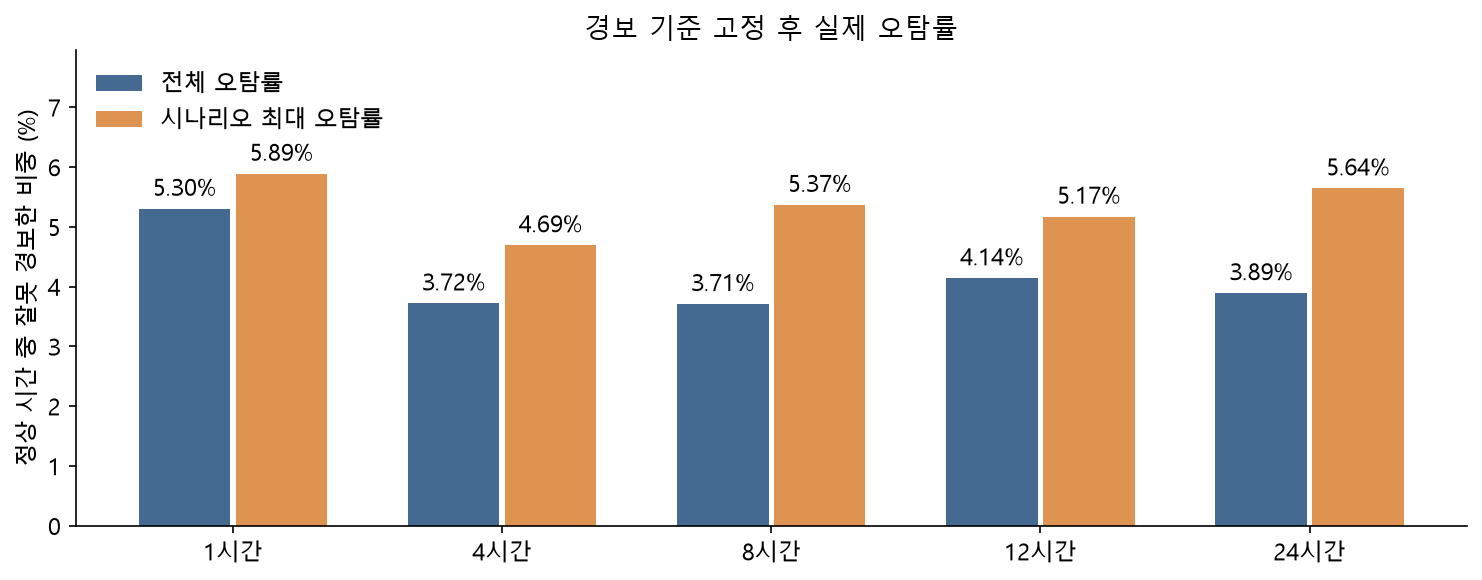

In [4]:
display(table()[['분석 구간', '전체 오탐률', '시나리오 최대 오탐률']])
display(Image(filename=str(OUT / 'figures/false_positive_rates.png')))

## 5. 여섯 시나리오에서의 성능

중앙값 하나만 보면 매우 약한 시나리오가 가려질 수 있다. 여섯 개를 모두 표시한다. 특히 4시간 입력 감소와 24시간 일일 패턴 변화는 기존 모델의 약점으로 남는다. 해당 길이 모델은 이번에 변경하지 않았다.

Recall 그림은 놓치는 이상을, F1 그림은 탐지율과 경보 정확도의 균형을 보여준다. 모든 개별 task가 잘 된 것으로 해석하지 않는다.

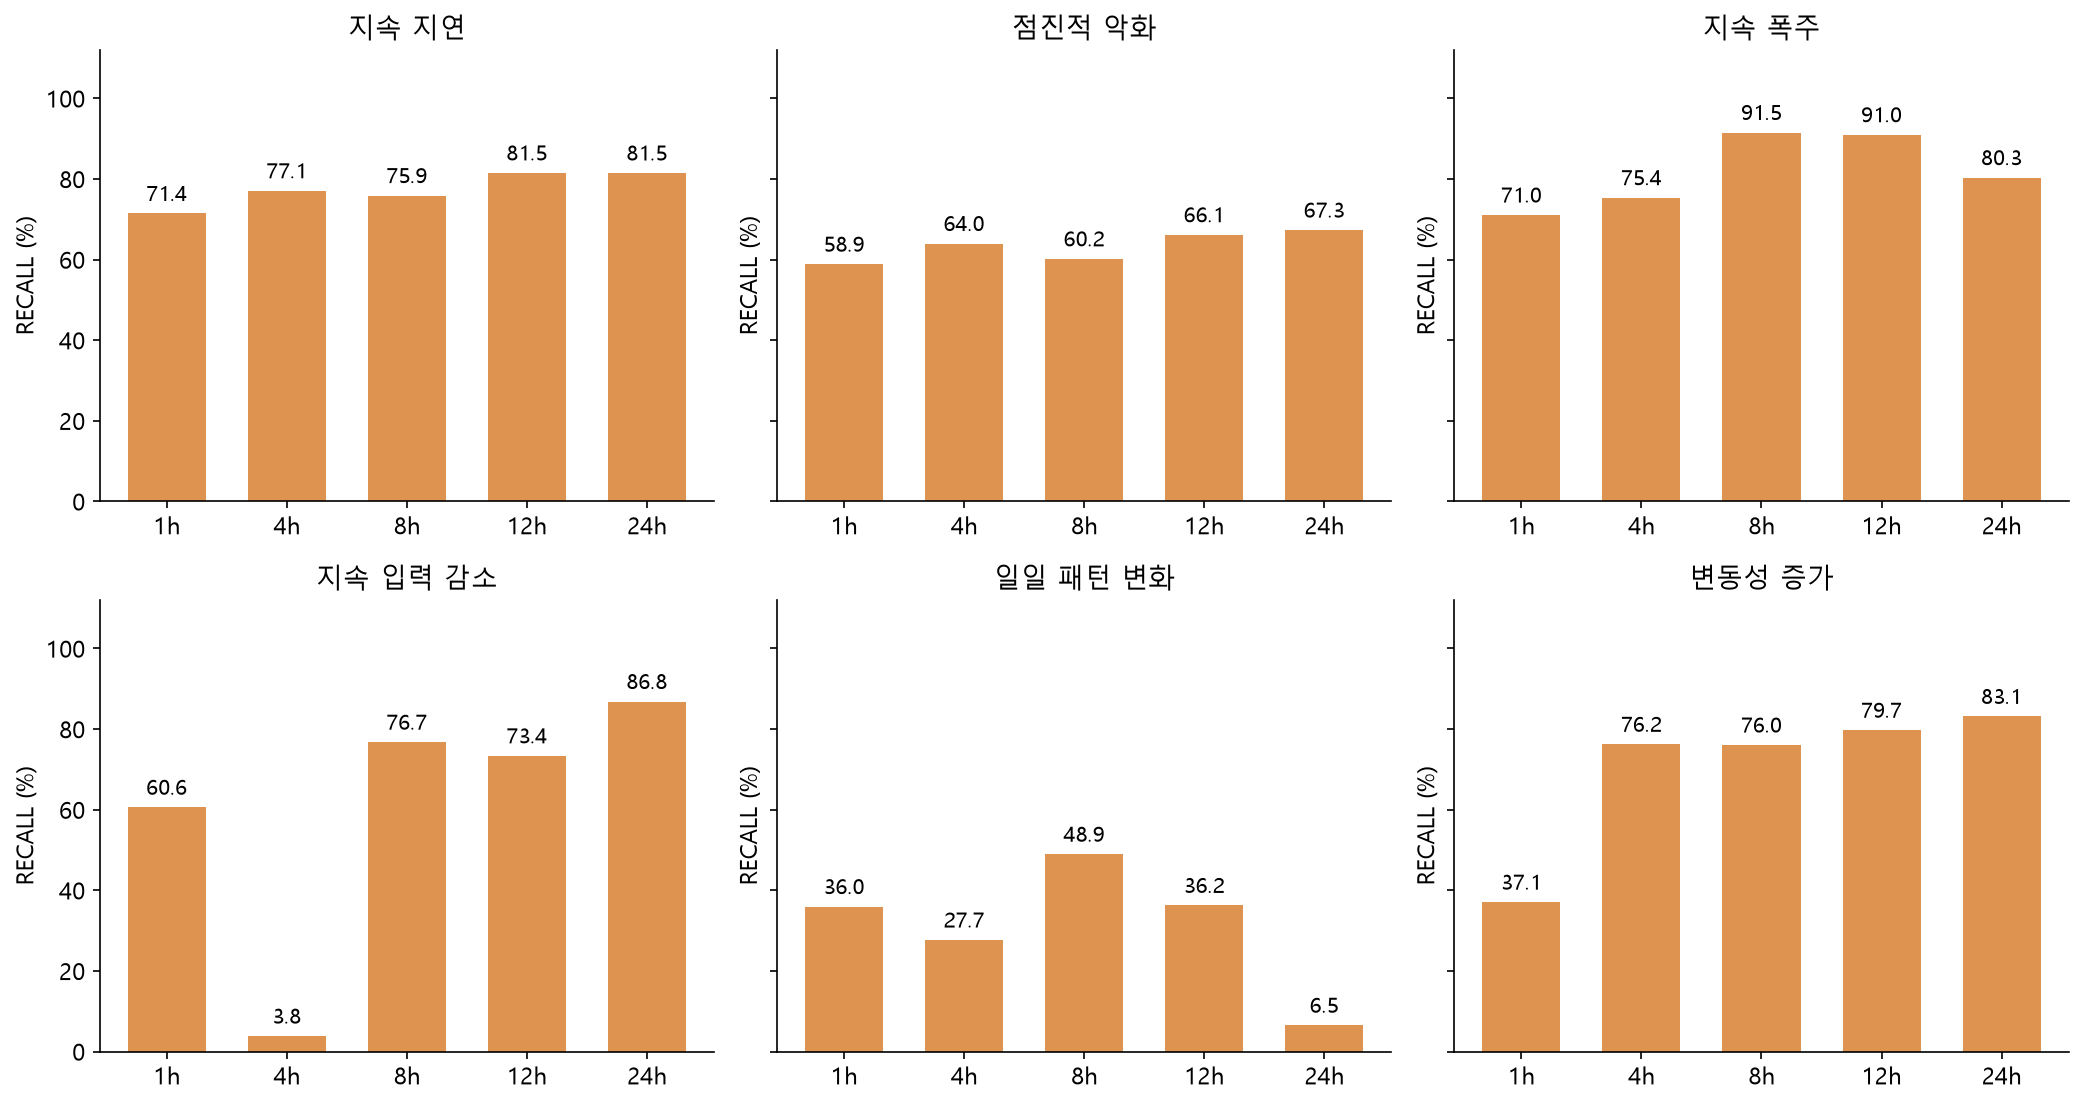

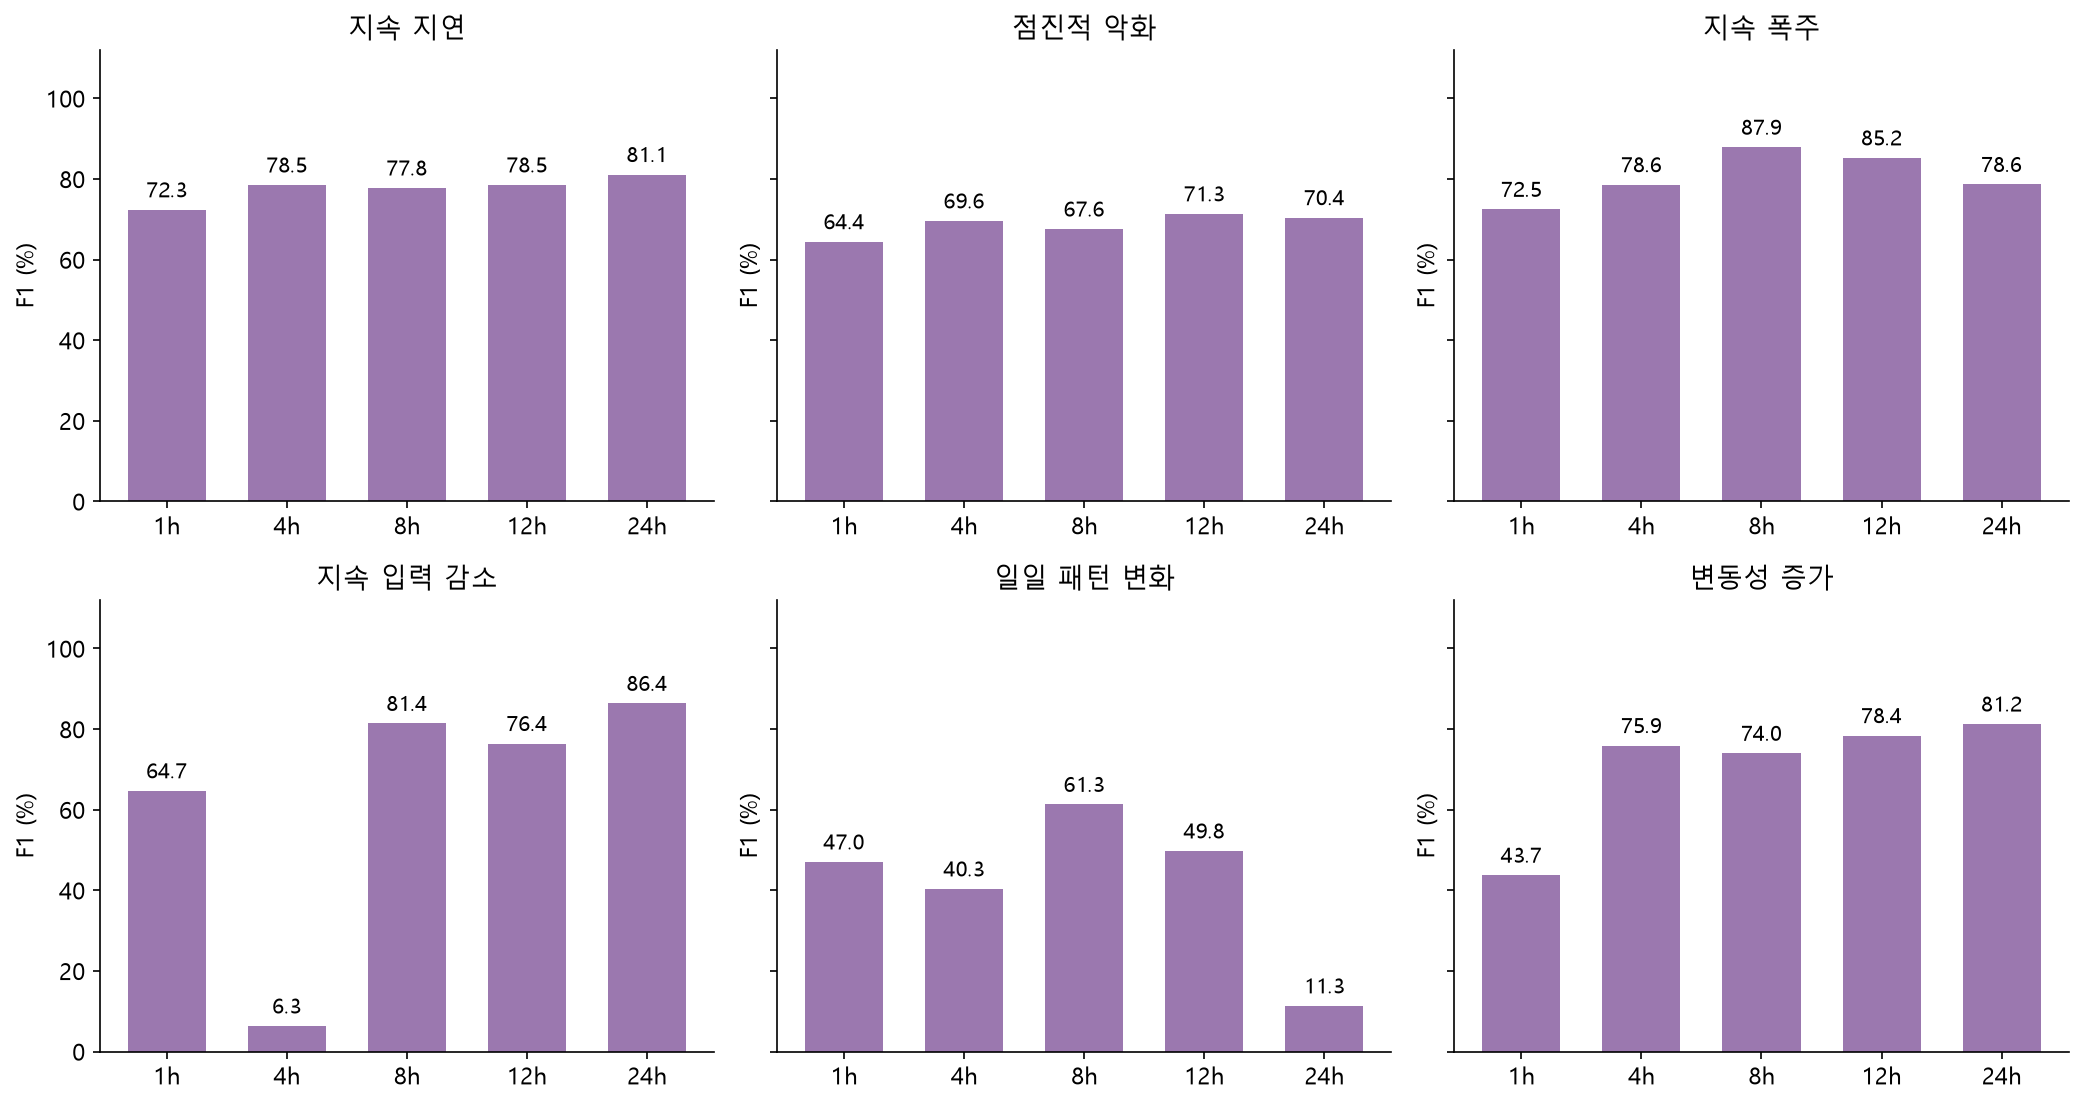

In [5]:
display(Image(filename=str(OUT / 'figures/scenario_recall.png')))
display(Image(filename=str(OUT / 'figures/scenario_f1.png')))

## 6. 1시간 개선 폭과 남은 목표

이전 1시간 모델과 같은 관측 시간·정답으로 비교했다. 아직 목표에 미치지 못한 값은 그대로 표시한다. 64%대 F1을 반올림해 65% 달성으로 처리하지 않는다.

이전·현재 모델의 차이는 정상 분포를 추정하는 방법이다. 입력에 다른 감시 구간을 추가하거나 평가 난도를 낮춘 차이가 아니다.

In [6]:
previous = read_json(ROOT / 'reports/long_term_anomaly/strict_intervals/results.json')['results']['1']
current = results['results']['1']
rows = [{'지표': name, '이전 중앙값(%)': 100*previous['median'][key], '현재 중앙값(%)': 100*current['median'][key], '변화(%p)': 100*(current['median'][key]-previous['median'][key])} for key, name in zip(('accuracy','precision','recall','f1'), ('Accuracy','Precision','Recall','F1'))]
display(pd.DataFrame(rows).round(2))
display(scenario_table(1))
display(Markdown(f"1시간 목표 충족: **{current['target_met']}**. 전체 길이 목표 충족: **{results['goal_met_all_lengths']}**."))

,지표,이전 중앙값(%),현재 중앙값(%),변화(%p)
0,Accuracy,87.62,88.69,1.06
1,Precision,63.37,70.27,6.90
2,Recall,48.08,59.72,11.64
3,F1,54.68,64.56,9.88


,시나리오,Accuracy,Precision,Recall,F1,오탐률
0,일일 패턴 변화,79.77,67.97,35.95,47.03,5.64
1,점진적 악화,87.60,71.17,58.85,64.43,5.62
2,지속 지연,90.97,73.27,71.43,72.34,5.16
3,지속 입력 감소,89.77,69.36,60.60,64.68,4.89
4,지속 폭주,91.54,73.92,71.05,72.46,4.66
5,변동성 증가,85.33,53.38,37.05,43.74,5.89


1시간 목표 충족: **False**. 전체 길이 목표 충족: **False**.

## 7. 점수 분포와 경보 기준

실제 threshold로 나눈 점수다. **1을 초과하면 경보**다. 파란색은 정상 정답, 주황색은 이상 정답이며 각 집단을 각각 100%로 정규화했다.

범위 밖 값은 제거하지 않고 양끝 막대에 모두 포함했다. 이 그림 처리는 실제 원래 점수로 계산한 지표와 무관하다. 점수는 확률이 아니며 음수도 정상적으로 나올 수 있다.

두 분포가 겹치는 영역이 크면 한쪽만 완벽하게 분리하기 어렵다. 이것이 모든 가능한 모델의 수학적 불가능성을 증명하는 것은 아니다.

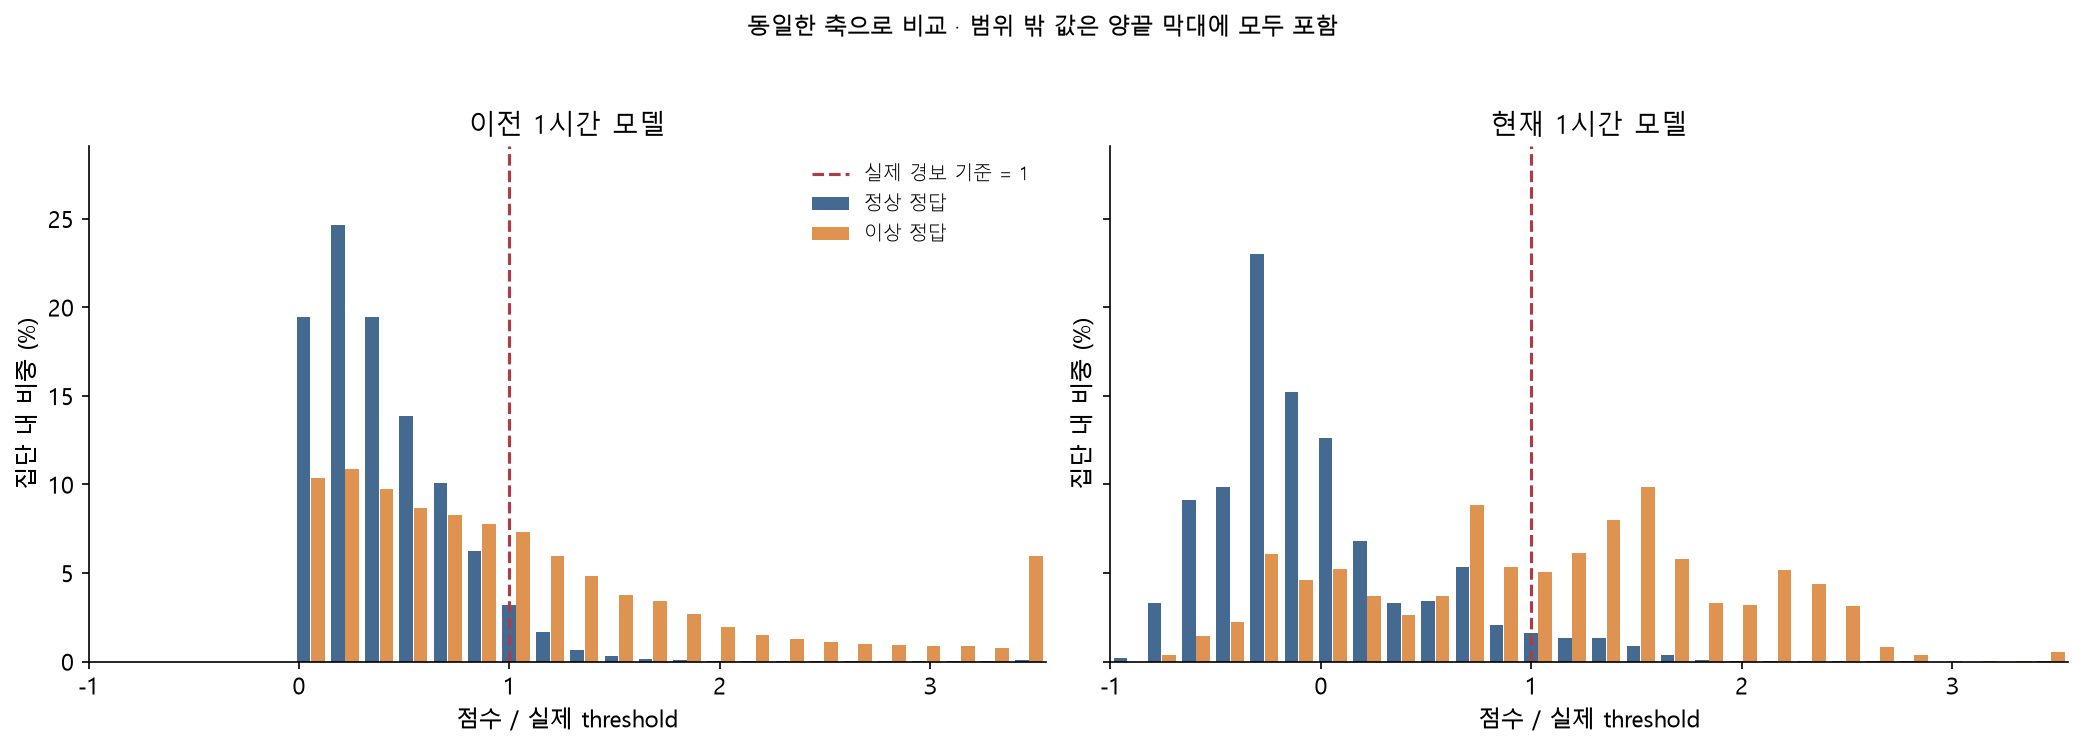

In [7]:
display(Image(filename=str(OUT / 'figures/one_hour_score_distribution.png')))

## 8. 점진적 악화 사례

좋은 점수로 골라낸 사례가 아니라 파일 순서상 첫 점진적 악화 주입 사례다. 주황 배경은 보고서에만 쓰는 원래 이상 정답이고 모델 입력은 아니다.

현재 값이 평소 수준에서 멀어질수록 경보 근거가 커질 수 있다. 다만 한 시간 모드가 과거 감시값의 증가 추세를 계산한 것은 아니다.

가장 크게 기여한 '넓어진 분포' 가설도 현재 한 점이 그런 가설에 더 그럴듯하다는 뜻이다. 현재 한 시간의 표준편차를 측정했거나 변동성 장애를 확정했다는 뜻이 아니다. 정상 시간의 큰 오탐 점수도 그대로 포함했다. 그림의 표시 상한을 넘는 값은 삼각형과 실제 수치로 표시하며, 지표는 원래 점수로 계산했다.

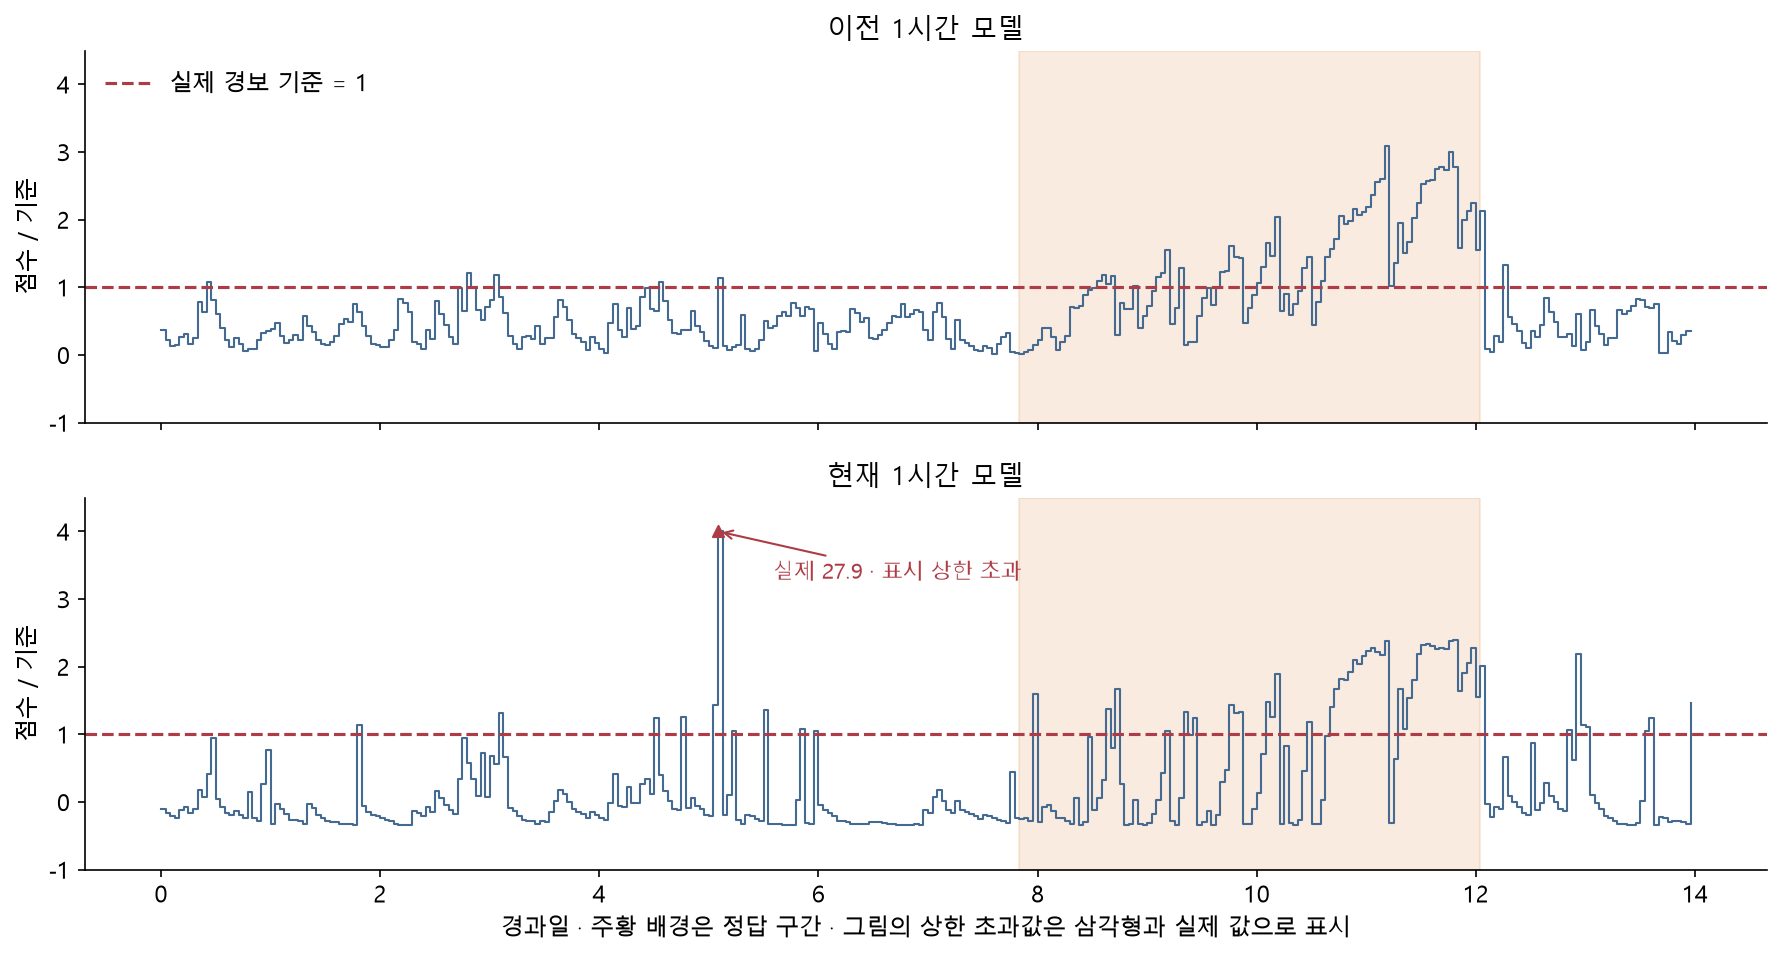

In [8]:
display(Image(filename=str(OUT / 'figures/one_hour_gradual_case.png')))

## 9. 중앙값과 통합 지표를 구분

아래는 모든 관측 시간의 TP·FP·TN·FN을 합쳐 다시 계산한 지표다. 앞서 목표로 정한 여섯 시나리오 지표의 중앙값과 다르다.

중앙값을 통과한 길이도 통합 Recall·F1이 낮을 수 있다. 시나리오별 난도와 이상 시간 수가 다르므로 실제 운영 판단에서는 두 결과를 함께 봐야 한다.

,분석 구간,Accuracy,Precision,Recall,F1,전체 오탐률,시나리오 최대 오탐률
0,1시간,87.50,69.02,54.36,60.82,5.30,5.89
1,4시간,88.42,75.33,52.27,61.72,3.72,4.69
2,8시간,91.46,80.22,69.23,74.32,3.71,5.37
3,12시간,90.92,78.15,68.17,72.82,4.14,5.17
4,24시간,90.08,77.68,62.33,69.16,3.89,5.64


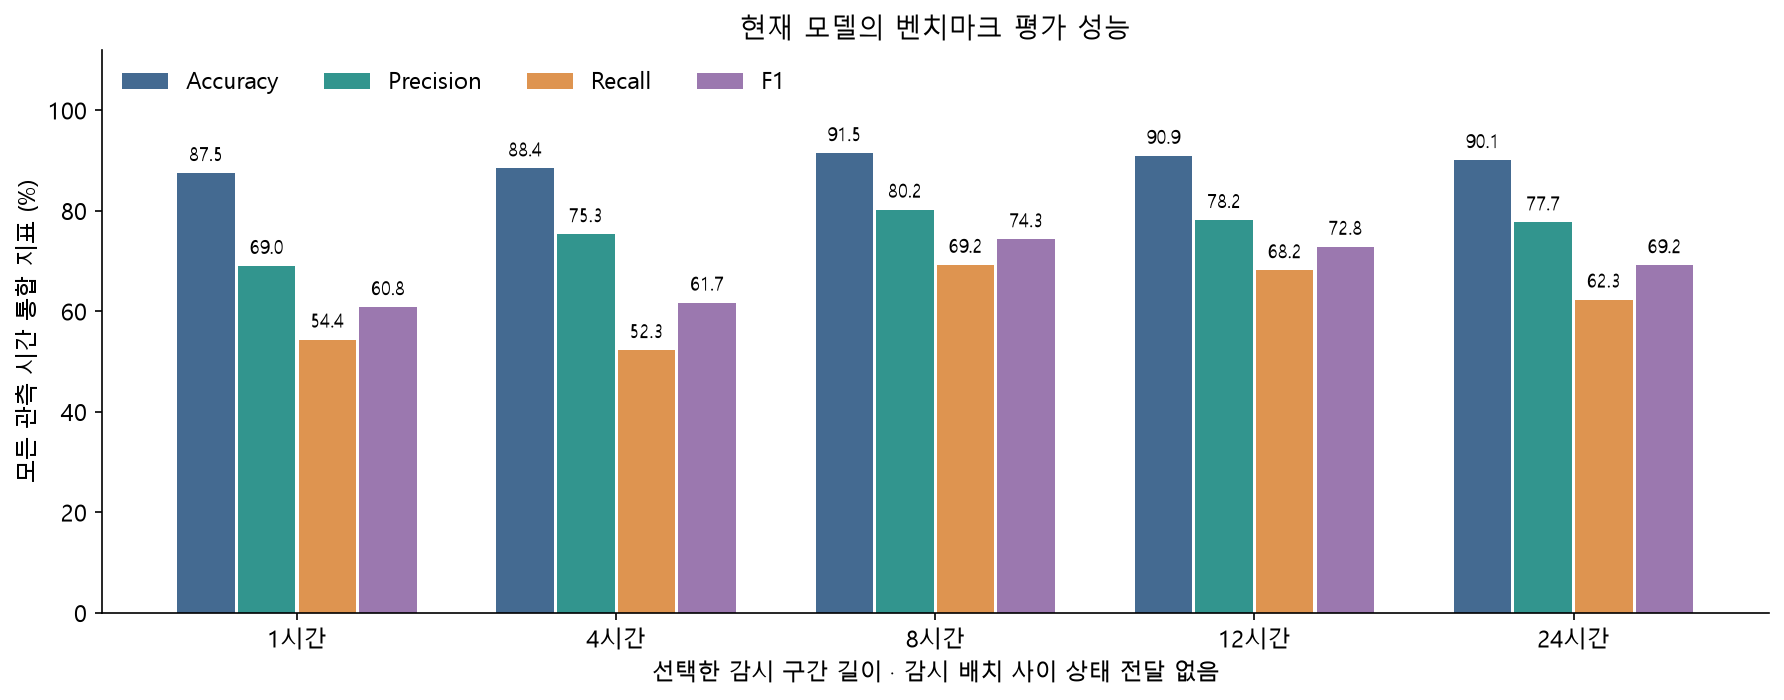

In [9]:
display(table('pooled'))
display(Image(filename=str(OUT / 'figures/metrics_pooled.png')))

## 10. 검증과 backend 사용

기존 원본 데이터·모델·노트북·평가셋의 해시를 검사하고, 모든 시간·시나리오의 혼동행렬을 독립 재계산했다. 30개 전체 backend API 재생도 저장 점수와 비교했다.

```python
from long_term_anomaly.strict_refinement.model import load_bank
bank = load_bank('reports/long_term_anomaly/strict_refinement/models.joblib')
reference = bank.prepare_reference(normal_history_28days)
result = bank.predict_batch(reference, current_1hour, analysis_hours=1)
```

원본 Process CSV가 아니라 시간별 집계 입력이다. 1·4·8·12·24시간을 선택할 수 있다. 정상 참고 통계만 메모리에 유지하며 감시 자료를 정상으로 자동 편입하지 않는다. code/long_term_anomaly 패키지와 같은 환경이 필요하다. 실제 입력 계약은 README.md에 있다.

In [10]:
verification = read_json(OUT / 'validation.json')
display(pd.DataFrame([{'검증 항목': k, '확인': v} for k,v in verification['checks'].items()]))
display(pd.DataFrame([{'분석 구간': f'{h}시간', '수치 목표 충족': v} for h,v in verification['goal_per_length'].items()]))
display(Markdown(f"무결성·추론·지표 검증: **{verification['integrity_passed']}**. 전체 수치 목표 달성: **{verification['goal_met_all_lengths']}**. 두 결과는 별개다."))

,검증 항목,확인
0,all_original_data_models_notebooks_and_reports...,True
1,all_three_original_periods_unchanged,True
2,source_model_selection_and_score_seals_match,True
3,selection_on_development_and_no_new_blind_test...,True
4,all_original_observed_hours_used_for_all_lengths,True
5,all_30_scenario_metrics_and_five_pooled_metric...,True
6,all_four_metric_medians_and_each_FPR_constrain...,True
7,other_four_providers_and_all_their_test_scores...,True
8,thirty_full_backend_API_replays_without_file_i...,True
9,no_monitoring_history_or_automatic_normal_updates,True


,분석 구간,수치 목표 충족
0,1시간,False
1,4시간,True
2,8시간,True
3,12시간,True
4,24시간,True


무결성·추론·지표 검증: **True**. 전체 수치 목표 달성: **False**. 두 결과는 별개다.

## 11. 추가 개발셋 탐색 — 최종 테스트 결과와 구분

정상 변동 폭의 공동 추정, 시간대·추세·자기상관 보정, 집단별 점수 보정, 정상 관측 분포 직접 학습, 같은 한 시간 안의 실행 횟수·소요시간 공동 신호를 추가로 비교했다. 이후 작은 이동 가설의 세분화, 정상 분위수 보정, 정상 AR 피처·인공 잡음 구분 학습도 비교했다. 정상 학습 구간의 과거 1·2·4·8시점 관계와 정상 집단별 경보 기준을 회귀로 보정하는 방법까지 비교했다. 아래 숫자는 **모두 개발셋에서의 시나리오별 중앙값**이다. 위의 최종 테스트 성능과 섞어서 읽지 않는다.

추가 후보는 개발셋에서도 Recall 목표에 못 미쳤으므로 최종 모델에 반영하지 않았다. 후보들의 테스트는 새로 평가하지 않았고 기존 저장 모델·정답·평가 난도는 변경하지 않았다. 후보가 많으므로 개발셋에 대한 과적합 가능성도 있다.

현재 1시간 입력은 한 점이다. 추가 실험도 구간 밖 감시 자료나 누적 상태를 사용하지 않으며, 과거 28일의 검토된 정상 참고 통계만 사용한다. 더 촘촘한 평가 자료는 아직 생성하지 않았다.

정상·인공 잡음 구분 후보는 정상 train의 앞 672시간을 참고 자료, 뒤 336시간의 정상 관측을 학습 질의로 사용했다. 기존 최종 모델과 학습 범위가 다르지만 실제 평가 이상 정답을 분포 학습에 넣거나 평가 자료를 바꾼 것은 아니다. 별도의 개발셋 정답 학습 분류기는 4개 집단 분리 폴드에서 진단만 했고 이 표나 최종 모델에 포함하지 않았다. 어느 진단도 모든 가능한 모델의 불가능성을 증명하지는 않는다.

In [11]:
from long_term_anomaly.strict_refinement.report import development_study_table
display(development_study_table())

,개발셋 비교,Accuracy,Precision,Recall,F1,시나리오 최대 오탐률(%),최종 모델 반영
0,현재 저장 모델,88.58,69.09,63.15,66.12,5.90,True
1,정상 변동 폭 공동 추정,88.89,69.66,63.85,66.49,5.90,False
2,시간대·추세·자기상관 보정,88.91,69.85,63.69,66.35,5.89,False
3,집단별 경보 점수 보정,88.87,69.65,63.96,66.51,5.90,False
4,정상 관측 분포 직접 학습,88.91,71.76,61.88,65.97,5.90,False
5,실행 횟수·소요시간 공동 가설,88.90,70.20,63.99,66.54,5.90,False
6,작은 이동·변동 가설 세분화,88.88,70.08,64.11,66.57,5.89,False
7,정상 분위수에 맞춘 분포 보정,88.85,69.39,64.19,67.00,5.90,False
8,정상 과거 1·2·4·8시점 관계 학습,88.91,69.82,64.16,66.59,5.89,False
9,정상 집단별 경보 기준 회귀 보정,88.86,69.75,63.78,66.31,5.89,False


## 근거와 한계

[Bühlmann의 AR 잔차 재표본 원리](https://statistics.berkeley.edu/sites/default/files/tech-reports/431.pdf)와 [SciPy lfilter](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.lfilter.html)를 참고했다. 원 논문의 증가하는 AR 차수·이론 보장을 그대로 재현한 것은 아니다. 여기서는 고정 AR(1), 집단 간 정상 혁신 공유, 밀도비 점수를 적용했다.

평가셋의 정상 연속성도 AR형으로 생성되었으므로 이 모델에 유리할 수 있다. 기존 평가셋 재사용 결과를 새 독립 블라인드 평가나 실제 운영 성능으로 주장하지 않는다. 실제 정상 참고 구간의 품질과 새로운 데이터에서의 일반화 검증이 필요하다.